**Chiller Digital Twin 2: Energy Cost of Fouling and the Optimal Cleaning Interval**

Notebook `01` showed that holding the 7 °C chilled water supply costs extra compressor power as the condenser fouls. Here we turn that into money and CO₂, and find how often the condenser should be cleaned.

### Inputs (edit to suit your plant):

| | Default |
|---|---|
| Operating hours | 6000 h/year |
| Electricity tariff | 8 per kWh (₹) |
| Grid emission factor | 0.7 kg CO₂/kWh |
| Condenser cleaning cost | 5000 per cleaning |
| Fouling growth | asymptotic, $R_f(t) = R_{f,max}\,(1 - e^{-t/\tau})$, $R_{f,max}$ = 0.0005 m²K/W, $\tau$ = 60 days |

### Method:

1. IDAES sweep of the compressor power vs fouling at a constant 7 °C chilled water supply.
2. A quadratic fit of power vs $R_f$ (a surrogate of the IDAES model), used to integrate the extra power over a fouling cycle.
3. For each cleaning interval: annual cost = energy penalty (average extra power × hours × tariff) + cleaning cost × cleanings per year.

Frequent cleaning keeps the condenser clean but costs more in cleanings; rare cleaning saves cleanings but wastes energy. The optimum lies in between.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


In [2]:
from chiller import setup_chiller_model, chiller_results

# Build, initialize and solve the chiller at its design point
model, results = setup_chiller_model()
print(results.solver.termination_condition)
cop_clean = chiller_results(model)["COP"]
print("Design COP: {0:.3f}".format(cop_clean))

The DOF is 0
optimal
Design COP: 4.563


In [3]:
from chiller_case_studies import fouling_sweep, annual_penalty, power_surrogate

fouling = [0, 0.000176, 0.00035, 0.0005, 0.001]
sweep = fouling_sweep(model, fouling, mode="fixed_supply")

HOURS, TARIFF, CO2 = 6000, 8.0, 0.7
penalty = annual_penalty(sweep, hours=HOURS, tariff=TARIFF, co2_factor=CO2)
penalty

,Compressor power (kW),Extra power (kW),Extra energy (kWh/yr),Extra cost (per yr),Extra CO2 (t/yr),COP
Fouling resistance (m2K/W),,,,,,
0.000000,4.602629,0.000000,0.000000,0.000000,0.000000,4.558393
0.000176,4.931367,0.328737,1972.424505,15779.396040,1.380697,4.254519
0.000350,5.286248,0.683619,4101.713104,32813.704830,2.871199,3.968901
0.000500,5.618276,1.015647,6093.882309,48751.058475,4.265718,3.734347
0.001000,6.948537,2.345908,14075.447408,112603.579263,9.852813,3.019426


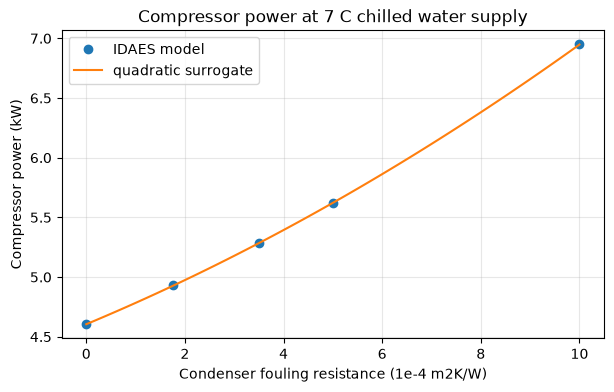

In [4]:
import numpy as np
import matplotlib.pyplot as plt

power = power_surrogate(sweep)
rf = np.linspace(0, 0.001, 50)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep.index * 1e4, sweep["Compressor power (kW)"], "o", label="IDAES model")
ax.plot(rf * 1e4, power(rf), "-", label="quadratic surrogate")
ax.set_xlabel("Condenser fouling resistance (1e-4 m2K/W)")
ax.set_ylabel("Compressor power (kW)")
ax.set_title("Compressor power at 7 C chilled water supply")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Optimal cleaning interval

In [5]:
from chiller_case_studies import cleaning_interval_study, fouling_growth

CLEANING_COST = 5000.0
intervals = [15, 30, 45, 60, 75, 90, 120, 150, 180, 270, 365]
cleaning = cleaning_interval_study(power, intervals, rf_max=0.0005, tau_days=60,
                                   hours_per_day=HOURS / 365, tariff=TARIFF, cleaning_cost=CLEANING_COST)
best = cleaning["Total cost (per yr)"].idxmin()
print("Optimal cleaning interval: {0} days".format(best))
print("Annual saving vs cleaning once a year: {0:,.0f}".format(
    cleaning.loc[365, "Total cost (per yr)"] - cleaning.loc[best, "Total cost (per yr)"]))
cleaning

Optimal cleaning interval: 120 days
Annual saving vs cleaning once a year: 3,670


,Average extra power (kW),Energy penalty (per yr),Cleaning cost (per yr),Total cost (per yr)
Cleaning interval (days),,,,
15,0.102062,4898.959161,121666.666667,126565.625828
30,0.192797,9254.258881,60833.333333,70087.592214
45,0.272898,13099.082128,40555.555556,53654.637683
60,0.343317,16479.226904,30416.666667,46895.893571
75,0.405096,19444.628426,24333.333333,43777.961759
90,0.459262,22044.582564,20277.777778,42322.360342
120,0.548508,26328.388377,15208.333333,41536.721710
150,0.617629,29646.184688,12166.666667,41812.851354
180,0.671703,32241.736828,10138.888889,42380.625717


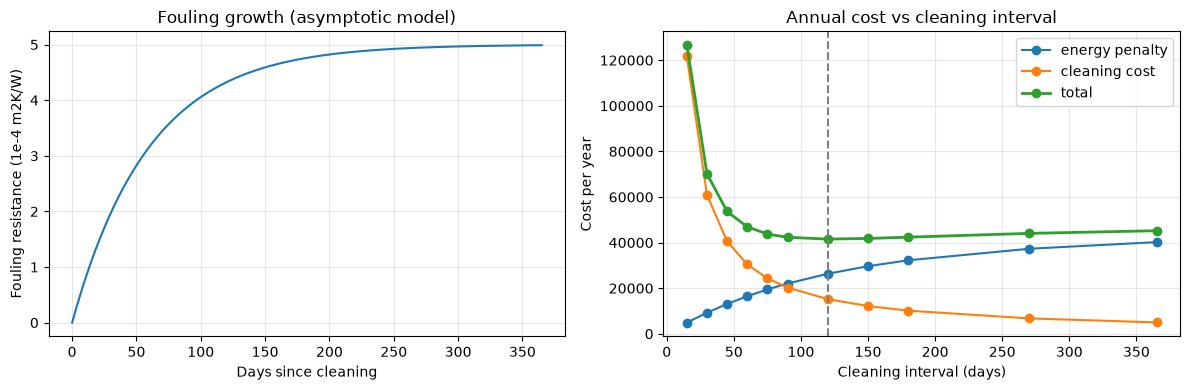

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
t = np.linspace(0, 365, 366)
ax1.plot(t, fouling_growth(t) * 1e4)
ax1.set_xlabel("Days since cleaning")
ax1.set_ylabel("Fouling resistance (1e-4 m2K/W)")
ax1.set_title("Fouling growth (asymptotic model)")
ax1.grid(alpha=0.3)
ax2.plot(cleaning.index, cleaning["Energy penalty (per yr)"], "o-", label="energy penalty")
ax2.plot(cleaning.index, cleaning["Cleaning cost (per yr)"], "o-", label="cleaning cost")
ax2.plot(cleaning.index, cleaning["Total cost (per yr)"], "o-", label="total", linewidth=2)
ax2.axvline(best, color="grey", linestyle="--")
ax2.set_xlabel("Cleaning interval (days)")
ax2.set_ylabel("Cost per year")
ax2.set_title("Annual cost vs cleaning interval")
ax2.grid(alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.show()